In [1]:
import pm4py
import pandas as pd

from pm4py.objects.petri_net.obj import PetriNet
from pm4py.objects.petri_net.utils import petri_utils
from pm4py.visualization.petri_net import visualizer as pn_visualizer

print("PM4Py version:", pm4py.__version__)
print("Libraries imported successfully!")



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




PM4Py version: 2.7.23.9
Libraries imported successfully!


In [2]:
from pm4py.objects.process_tree.obj import ProcessTree, Operator

# Helper function for optional activities
def optional_activity(activity):
    return ProcessTree(
        operator=Operator.XOR,
        children=[
            ProcessTree(label=activity),
            ProcessTree()
        ]
    )

# Define final outcome
final_outcome = ProcessTree(
    operator=Operator.XOR,
    children=[
        ProcessTree(label="Discharge"),
        ProcessTree(label="Admission")
    ]
)

# Create ideal hospital pathway
ideal_process_tree = ProcessTree(
    operator=Operator.SEQUENCE,
    children=[
        ProcessTree(label="Registration"),
        ProcessTree(label="Triage"),

        optional_activity("Lab Test"),
        optional_activity("X-Ray"),
        optional_activity("Imaging"),

        ProcessTree(label="Treatment"),
        ProcessTree(label="Doctor Consultation"),

        final_outcome
    ]
)

print("Ideal hospital process tree created successfully!")

Ideal hospital process tree created successfully!


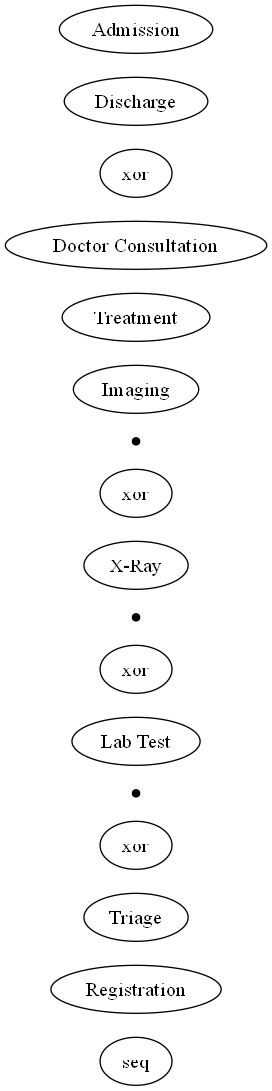

Ideal process tree saved successfully!


In [3]:
#Visualize the ideal process tree
from pm4py.visualization.process_tree import visualizer as pt_visualizer

gviz = pt_visualizer.apply(ideal_process_tree)

pt_visualizer.save(
    gviz,
    "ideal_hospital_process_tree.png"
)

pt_visualizer.view(gviz)

print("Ideal process tree saved successfully!")

In [4]:
#Convert the process tree into a Petri Net
# Convert Process Tree into Petri Net

net, initial_marking, final_marking = pm4py.convert_to_petri_net(
    ideal_process_tree
)

print("Petri Net created successfully!")
print("Number of places:", len(net.places))
print("Number of transitions:", len(net.transitions))
print("Initial marking:", initial_marking)
print("Final marking:", final_marking)

Petri Net created successfully!
Number of places: 9
Number of transitions: 12
Initial marking: ['source:1']
Final marking: ['sink:1']


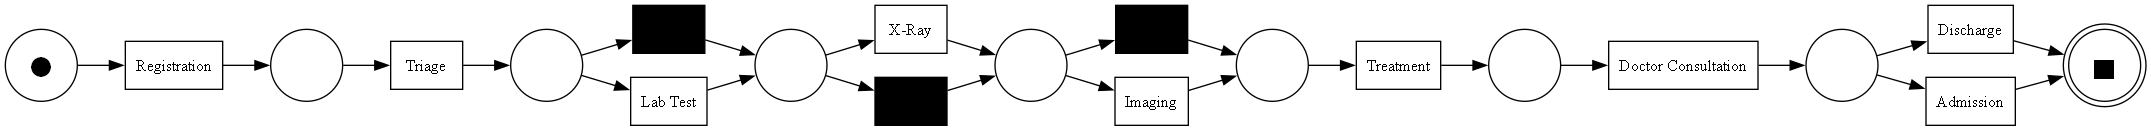

Ideal Petri Net saved successfully!


In [5]:
#. Visualize the ideal Petri Net
gviz = pn_visualizer.apply(
    net,
    initial_marking,
    final_marking
)

pn_visualizer.save(
    gviz,
    "ideal_hospital_petri_net.png"
)

pn_visualizer.view(gviz)

print("Ideal Petri Net saved successfully!")

In [6]:
#Save the reference model
# Save Petri Net as PNML

pm4py.write_pnml(
    net,
    initial_marking,
    final_marking,
    "ideal_reference_model.pnml"
)

print("Reference model saved successfully!")

Reference model saved successfully!
